# 02 · Parte 1: HMM y regresión logística implementados por el equipo

1. **HMM gaussiano** de 3 estados (Normal / Alerta / Episodio crítico) sobre log(PM2.5) diario, con forward-backward escalado, Baum-Welch para múltiples secuencias con datos faltantes y Viterbi (`src/aire/hmm.py`).
2. **Regresión logística multinomial** con Adam y L2 (`src/aire/classifier.py`) para predecir la categoría ICA del día siguiente, usando como variables las probabilidades filtradas del HMM (integración de ambas técnicas).
3. **Evaluación temporal** con origen móvil mensual frente a líneas base (`src/aire/modeling.py`).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 140)
from aire import config as C
from aire.hmm import GaussianHMM
from aire.classifier import SoftmaxRegression
import itertools

## 1. Verificación de corrección del HMM
### 1a. Forward escalado vs. enumeración exhaustiva de caminos ocultos

In [2]:
rng = np.random.default_rng(0)
h = GaussianHMM(n_states=3)
h.pi = np.array([.5,.3,.2]); h.A = np.array([[.8,.15,.05],[.1,.8,.1],[.05,.15,.8]])
h.mu = np.array([0., 1., 2.]); h.var = np.array([.2,.3,.4])
x = rng.normal(1, 1, 6); x[2] = np.nan  # con un dato faltante
B = h._emission(x); brute = 0.0
for path in itertools.product(range(3), repeat=len(x)):
    p = h.pi[path[0]] * B[0, path[0]]
    for t in range(1, len(x)): p *= h.A[path[t-1], path[t]] * B[t, path[t]]
    brute += p
print('log p(x) forward  :', h.loglik(x))
print('log p(x) enumerado:', np.log(brute))
best = max(itertools.product(range(3), repeat=len(x)), key=lambda pth: np.prod([h.pi[pth[0]]*B[0,pth[0]]] + [h.A[pth[t-1],pth[t]]*B[t,pth[t]] for t in range(1,len(x))]))
print('Viterbi:', h.viterbi(x), '| enumerado:', np.array(best))

log p(x) forward  : -4.384768584726757
log p(x) enumerado: -4.384768584726758
Viterbi: [1 1 1 1 1 1] | enumerado: [1 1 1 1 1 1]


### 1b. Baum-Welch recupera los parámetros de datos simulados

In [3]:
def simulate(h, T, rng):
    z = [rng.choice(3, p=h.pi)]
    for _ in range(T-1): z.append(rng.choice(3, p=h.A[z[-1]]))
    z = np.array(z); return rng.normal(h.mu[z], np.sqrt(h.var[z])), z
seqs = [simulate(h, 300, rng)[0] for _ in range(10)]
fit = GaussianHMM(n_states=3).fit(seqs)
print('mu real', h.mu, '| estimada', fit.mu.round(2))
print('var real', h.var, '| estimada', fit.var.round(2))
print('A estimada\n', fit.A.round(2))
print('Log-verosimilitud monótona en EM:', bool(np.all(np.diff(fit.history) > -1e-6)))

mu real [0. 1. 2.] | estimada [-0.    0.94  1.89]
var real [0.2 0.3 0.4] | estimada [0.19 0.26 0.44]
A estimada
 [[0.8  0.14 0.06]
 [0.1  0.78 0.12]
 [0.06 0.19 0.75]]
Log-verosimilitud monótona en EM: True


## 2. HMM sobre los datos reales del SIATA

In [4]:
from aire.data import daily_matrix, active_stations
from aire.modeling import fit_hmm, hmm_filtered
M = daily_matrix(); logm = np.log(M)
hmm = fit_hmm(logm)
print('Medias de emisión (µg/m³):', dict(zip(C.ESTADOS_HMM, np.exp(hmm.mu).round(1))))
print('Desv. est. en log:', np.sqrt(hmm.var).round(3))
pd.DataFrame(hmm.A, index=C.ESTADOS_HMM, columns=C.ESTADOS_HMM).round(3)

Medias de emisión (µg/m³): {'Normal': np.float64(12.3), 'Alerta': np.float64(18.1), 'Episodio crítico': np.float64(29.6)}
Desv. est. en log: [0.256 0.207 0.213]


,Normal,Alerta,Episodio crítico
Normal,0.949,0.051,0.000
Alerta,0.036,0.936,0.028
Episodio crítico,0.010,0.053,0.937


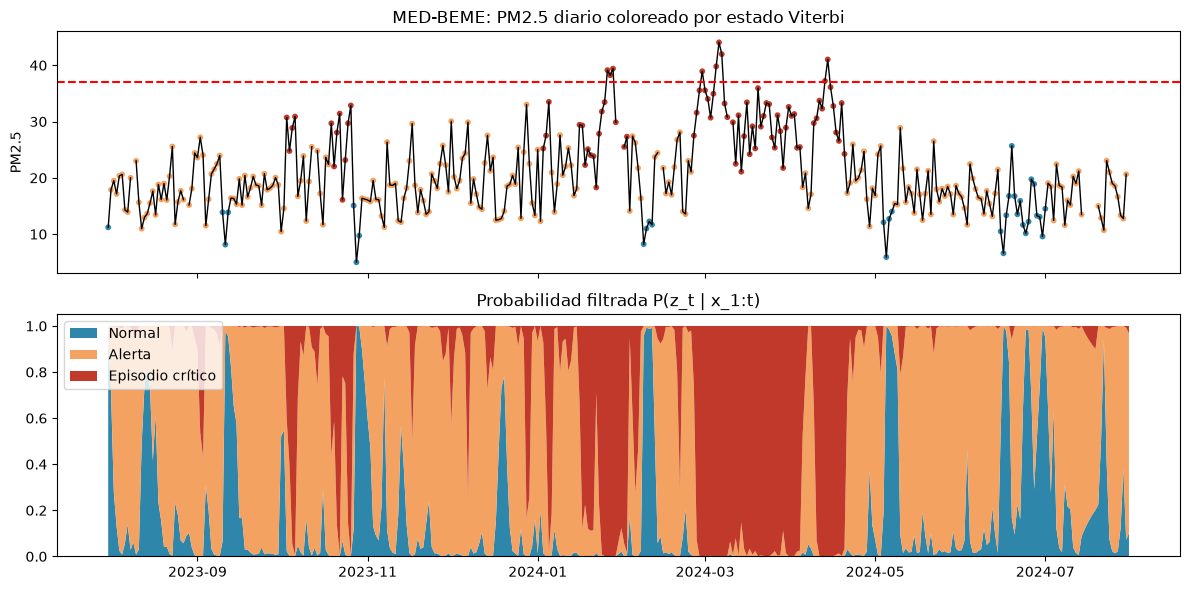

In [5]:
code = 83  # MED-BEME (Belén)
f = hmm.filter(logm[code].to_numpy()); v = hmm.viterbi(logm[code].to_numpy())
fig, ax = plt.subplots(2, 1, figsize=(12,6), sharex=True)
ax[0].plot(M.index, M[code], color='k', lw=1); ax[0].scatter(M.index, M[code], c=[C.COLORES_ESTADOS[s] for s in v], s=10)
ax[0].axhline(37, color='red', ls='--'); ax[0].set_ylabel('PM2.5'); ax[0].set_title('MED-BEME: PM2.5 diario coloreado por estado Viterbi')
ax[1].stackplot(M.index, f.T, colors=C.COLORES_ESTADOS, labels=C.ESTADOS_HMM); ax[1].legend(loc='upper left'); ax[1].set_title('Probabilidad filtrada P(z_t | x_1:t)')
plt.tight_layout(); plt.show()

In [6]:
from aire.ica import clase_3_array
states = np.concatenate([hmm.viterbi(logm[c].to_numpy()) for c in M.columns])
vals = np.concatenate([M[c].to_numpy() for c in M.columns])
ok = ~np.isnan(vals)
pd.crosstab(pd.Series(np.array(C.ESTADOS_HMM)[states[ok]], name='Estado HMM'), pd.Series(np.array(C.CLASES_CORTAS)[clase_3_array(vals[ok])], name='Categoría ICA'))

Categoría ICA,Aceptable,Buena,Dañina
Estado HMM,,,
Alerta,2550,122,0
Episodio crítico,970,0,172
Normal,1020,1036,0


El estado *Episodio crítico* concentra casi todos los días en categoría Dañina, pero también incluye días Aceptables de un periodo sostenido de contaminación. Es un régimen estadístico, no una declaratoria oficial del AMVA.

## 3. Evaluación temporal (origen móvil) frente a líneas base
Ejecuta lo mismo que `scripts/train_models.py` (≈1 min).

In [7]:
from aire.modeling import rolling_origin_evaluation
r = rolling_origin_evaluation()
tabla = pd.DataFrame({k: {'Exactitud': v['accuracy'], 'Exact. balanceada': v['balanced_accuracy'], 'F1 macro': v['macro_f1'],
  'Recall Dañina': v['recall_por_clase'][2], 'Log-loss': v.get('log_loss'), 'Brier': v.get('brier')} for k, v in r['resultados'].items()}).T
tabla.round(3)

,Exactitud,Exact. balanceada,F1 macro,Recall Dañina,Log-loss,Brier
Línea base: clase mayoritaria,0.757,0.333,0.287,0.000,NaN,NaN
Línea base: persistencia (mañana = hoy),0.799,0.685,0.684,0.601,NaN,NaN
Línea base: cadena de Markov de clases,0.796,0.654,0.664,0.506,0.536,0.300
HMM propio (predicción a un paso),0.758,0.339,0.300,0.000,0.522,0.313
Reg. logística propia: sólo info de hoy,0.795,0.669,0.661,0.565,0.448,0.275
Reg. logística propia: info de hoy + domingo (sin meteorología),0.813,0.674,0.684,0.524,0.434,0.262
Reg. logística propia: completa sin HMM,0.811,0.681,0.686,0.571,0.445,0.267
Reg. logística propia: completa + HMM (modelo final),0.808,0.703,0.686,0.631,0.439,0.265


In [8]:
print('Verificación con scikit-learn (misma función objetivo):', r['verificacion_sklearn'])
print('alpha elegido por validación interna:', r['alpha_por_mes'])
pd.DataFrame(r['hmm_loglik']).round(3)

Verificación con scikit-learn (misma función objetivo): {'acuerdo_argmax': 1.0, 'max_dif_probabilidad': 0.0059185941450976, 'media_dif_probabilidad': 0.0004556537423115733}
alpha elegido por validación interna: [{'mes': '2024-01', 'alpha': 0.5}, {'mes': '2024-02', 'alpha': 0.5}, {'mes': '2024-03', 'alpha': 0.5}, {'mes': '2024-04', 'alpha': 0.5}, {'mes': '2024-05', 'alpha': 0.25}, {'mes': '2024-06', 'alpha': 0.25}, {'mes': '2024-07', 'alpha': 0.5}]


,mes,n_obs,ll_hmm_por_obs,ll_iid_por_obs
0,2024-01,497,-0.346,-0.580
1,2024-02,483,-0.236,-0.533
2,2024-03,519,-0.255,-1.557
3,2024-04,477,-0.228,-0.654
4,2024-05,470,-0.133,-0.498
5,2024-06,462,-0.213,-0.690
6,2024-07,460,-0.018,-0.487


In [9]:
import json
met = json.loads((C.REPORTS_DIR / 'metricas_parte1.json').read_text(encoding='utf-8'))
for k in ['bootstrap_final_vs_persistencia', 'bootstrap_probabilistico_final_vs_markov', 'bootstrap_final_vs_sin_hmm']:
    print(k, json.dumps(met[k], indent=1))

bootstrap_final_vs_persistencia {
 "accuracy": {
  "media": 0.00889602349027824,
  "ic95": [
   -0.0075262120445395595,
   0.02448609431680771
  ]
 },
 "macro_f1": {
  "media": 0.001614647292537553,
  "ic95": [
   -0.031180776445898756,
   0.03765386347882198
  ]
 },
 "balanced_accuracy": {
  "media": 0.017424094896381817,
  "ic95": [
   -0.01843748344781003,
   0.060986548771634404
  ]
 }
}
bootstrap_probabilistico_final_vs_markov {
 "log_loss": {
  "media": -0.0975781882471331,
  "ic95": [
   -0.13294674655621094,
   -0.06437814143283475
  ]
 },
 "brier": {
  "media": -0.03565110045474941,
  "ic95": [
   -0.05086394932144433,
   -0.021239140560258423
  ]
 }
}
bootstrap_final_vs_sin_hmm {
 "accuracy": {
  "media": -0.0028154623169506007,
  "ic95": [
   -0.016178364513321004,
   0.008826450133437039
  ]
 },
 "macro_f1": {
  "media": -0.00026988285614025666,
  "ic95": [
   -0.02678485074211264,
   0.02803495222978108
  ]
 },
 "balanced_accuracy": {
  "media": 0.02188204247836114,
  "ic9

## 4. Interpretación del modelo final (coeficientes estandarizados)

In [10]:
clf = SoftmaxRegression.load(C.MODELS_DIR / 'clasificador.json')
pd.DataFrame(clf.coef_table()).set_index('variable').rename(columns=dict(zip(['clase_0','clase_1','clase_2'], C.CLASES_CORTAS))).round(3)

,Buena,Aceptable,Dañina
variable,,,
log_pm_hoy,-0.478,0.035,0.443
log_pm_ayer,-0.246,-0.000,0.246
delta_1d,-0.352,0.054,0.299
log_media_3d,-0.465,0.119,0.347
log_pm_valle_hoy,0.010,-0.186,0.176
hoy_buena,0.054,-0.037,-0.018
hoy_danina,-0.064,-0.116,0.180
p_alerta_hoy,-0.093,0.328,-0.235
p_critico_hoy,-0.376,0.016,0.361


## 5. Conclusiones y limitaciones
- La regresión logística con variables del HMM supera a la persistencia en exactitud (0.808 vs 0.799), exactitud balanceada (0.703 vs 0.685) y recall de la clase Dañina (0.63 vs 0.60), pero esas diferencias **no son estadísticamente significativas** (IC 95 % bootstrap incluye 0).
- En calidad probabilística sí hay mejora clara frente a la cadena de Markov de clases: log-loss 0.439 vs 0.536 y Brier 0.265 vs 0.300 (IC excluye 0).
- El HMM modela mucho mejor la serie que una gaussiana i.i.d. y sus variables mejoran de forma significativa la exactitud balanceada y la log-loss del clasificador.
- Como predictor directo (argmax), el HMM falla en las clases extremas: su estado más alto tiene media ≈30 µg/m³ (< 38).
- Limitaciones: un solo año de datos, 172 estación-días Dañinos, meteorología de reanálisis para un punto usada como pronóstico perfecto con signos poco intuitivos.